<a href="https://colab.research.google.com/github/Rahma000882/AI-Project/blob/main/HOUSE_PRICE_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from category_encoders import OneHotEncoder
import warnings
warnings.filterwarnings('ignore')

# Reading Dataset

In [ ]:
df = pd.read_csv('house-prices.csv')
df.shape

(128, 8)

# Data Overview

In [ ]:
def data_info(data):

    """
    This function returns a DataFrame containing the summary information for each column
    """

    Names=[col for col in data]
    data_types=[data[col].dtype for col in data.columns]
    top_10_unique_values=[data[col].value_counts().head(10).index.to_list() for col in data.columns]
    nunique_values=[data[col].nunique() for col in data.columns]
    nulls=[data[col].isnull().sum() for col in data.columns]
    percent_of_Nulls= [data[col].isnull().sum()/len(data)*100 for col in data.columns]
    duplicates=data.duplicated().sum()


    info_df=pd.DataFrame({'Name':Names,
                          'Data_Type':data_types,
                          'Top_10_Unique_Values':top_10_unique_values,
                          'Nunique_Values':nunique_values,
                          'Nulls':nulls,
                          'Percent_of_Nulls':percent_of_Nulls,
                          'Duplicates':duplicates})
    return info_df

In [ ]:
data_info(df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,Home,int64,"[1, 2, 95, 94, 93, 92, 91, 90, 89, 88]",128,0,0.0,0
1,Price,int64,"[117800, 125700, 105600, 103200, 129800, 11430...",123,0,0.0,0
2,SqFt,int64,"[1930, 2000, 1920, 2080, 2150, 2250, 1900, 199...",61,0,0.0,0
3,Bedrooms,int64,"[3, 2, 4, 5]",4,0,0.0,0
4,Bathrooms,int64,"[2, 3, 4]",3,0,0.0,0
5,Offers,int64,"[3, 2, 1, 4, 5, 6]",6,0,0.0,0
6,Brick,object,"[No, Yes]",2,0,0.0,0
7,Neighborhood,object,"[East, North, West]",3,0,0.0,0


# Preprocessing

## Check Nulls

In [ ]:
df.isnull().sum()

Home            0
Price           0
SqFt            0
Bedrooms        0
Bathrooms       0
Offers          0
Brick           0
Neighborhood    0
dtype: int64

# Check Duplicates

In [ ]:
df.duplicated().sum()

0

## Check Outliers

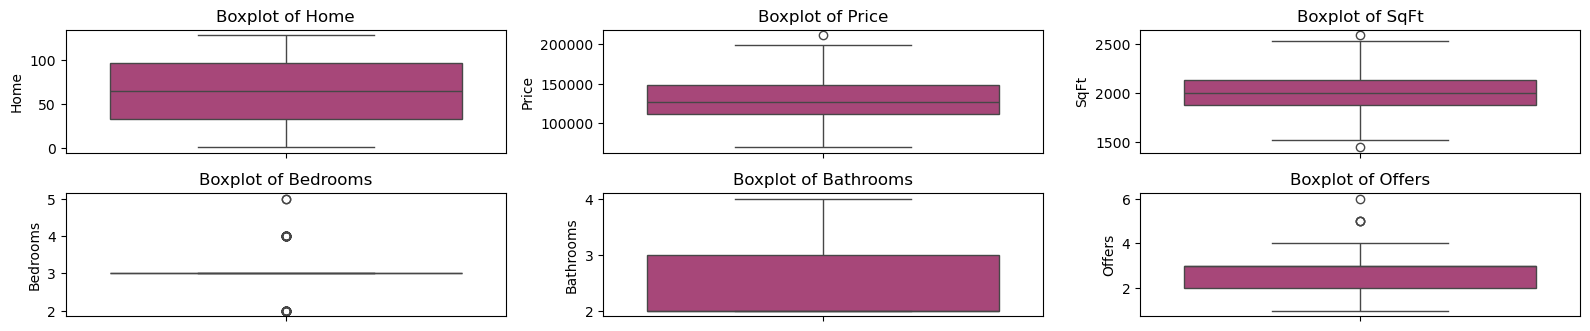

In [ ]:
Numerical_Columns = df.select_dtypes(include=['int64','float64']).columns.tolist()
fig, axes = plt.subplots(3, 3, figsize=(16, 5))

axes = axes.flatten()

for i, col in enumerate(Numerical_Columns):
    sns.boxplot(data=df, y=col, ax=axes[i], palette='magma',whis=1.5)
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [ ]:
# Function to handle outliers
def handle_Numerical_outliers(data):
    """
    This function handles outliers.
    """
    num_cols = data.select_dtypes(include="number").columns

    for col in num_cols:

        Q1=data[col].quantile(0.25)
        Q3=data[col].quantile(0.75)
        IQR=Q3-Q1

        lower_bound=Q1-(1.5*IQR)
        upper_bound=Q3+(1.5*IQR)

        data[col]=np.where(data[col]<lower_bound,lower_bound,data[col])
        data[col]=np.where(data[col]>upper_bound,upper_bound,data[col])

In [ ]:
handle_Numerical_outliers(df)

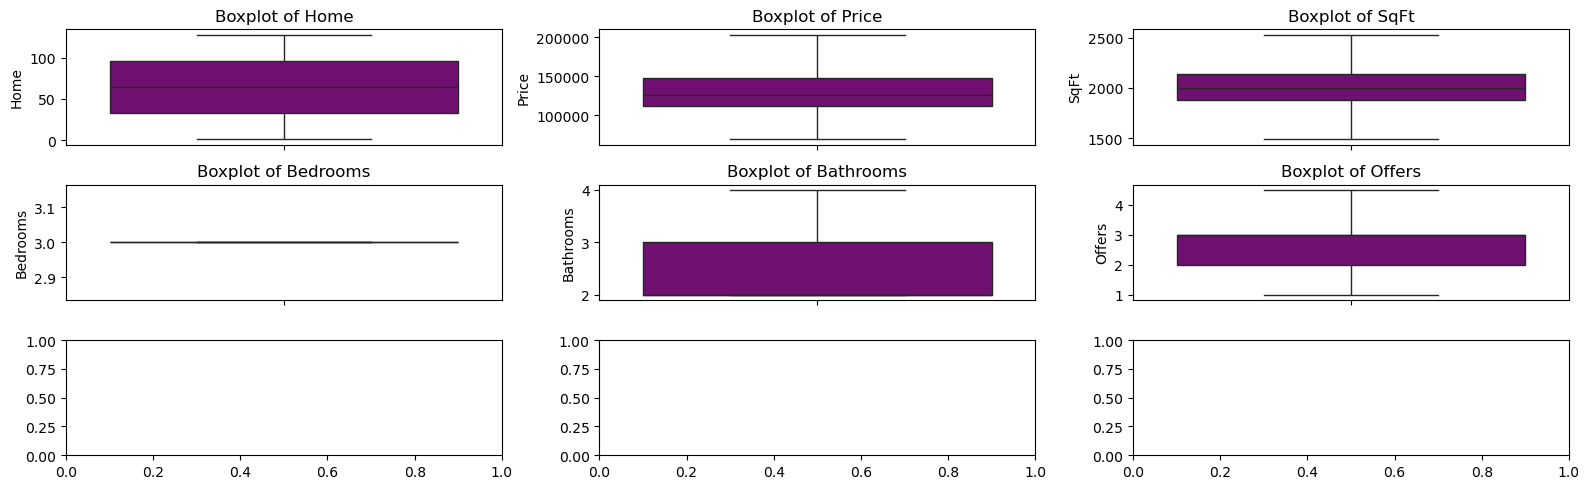

In [ ]:
n_cols = len(Numerical_Columns)

fig, axes = plt.subplots(3, 3, figsize=(16, 5))
axes = axes.flatten()

for i, col in enumerate(Numerical_Columns):
    sns.boxplot(
        data=df,
        y=col,
        ax=axes[i],
        color='purple',
        whis=1.5
    )
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()


# Splitting Data

In [ ]:
x = df.drop(columns=['Price'])
y = df['Price']

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

# Encoding

In [ ]:
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
one_hot_encoder=OneHotEncoder(cols=categorical_cols,use_cat_names=True)

x_train=one_hot_encoder.fit_transform(x_train)
x_test=one_hot_encoder.transform(x_test)

# Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

# Model Training

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
linear = LinearRegression()

In [ ]:
linear.fit(x_train, y_train)

LinearRegression()

# Model Evaluation

In [ ]:
y_pred_train=linear.predict(x_train)
y_pred_test=linear.predict(x_test)

In [ ]:
from sklearn import metrics
print("Train Data Evaluation Metrics")
print("MSE:",metrics.mean_squared_error(y_pred_train,y_train))
print("MAE:",metrics.mean_absolute_error(y_pred_train,y_train))
print("r2_score:",metrics.r2_score(y_pred_train,y_train))

print("####################################################################")

print("Test Data Evaluation Metrics")
print("MSE:",metrics.mean_squared_error(y_pred_test,y_test))
print("MAE:",metrics.mean_absolute_error(y_pred_test,y_test))
print("r2_score:",metrics.r2_score(y_pred_test,y_test))


Train Data Evaluation Metrics
MSE: 92073669.81695275
MAE: 7426.216706329706
r2_score: 0.8571801792187046
####################################################################
Test Data Evaluation Metrics
MSE: 124102540.48483779
MAE: 9130.7386387782
r2_score: 0.7691756370871783


# Lasso Regression

In [ ]:
from sklearn.linear_model import Lasso, Ridge

lasso=Lasso()
lasso.fit(x_train,y_train)

y_pred_lasso=lasso.predict(x_test)
print("Lasso Regression Test Data Evaluation Metrics")
print("MSE:",metrics.mean_squared_error(y_pred_lasso,y_test))
print("MAE:",metrics.mean_absolute_error(y_pred_lasso,y_test))
print("r2_score:",metrics.r2_score(y_pred_lasso,y_test))


Lasso Regression Test Data Evaluation Metrics
MSE: 124094031.02180693
MAE: 9130.476141605837
r2_score: 0.7691663787339376


# Ridge Regression

In [ ]:
ridge=Ridge()
ridge.fit(x_train,y_train)

y_pred_ridge=ridge.predict(x_test)
print("Ridge Regression Test Data Evaluation Metrics")
print("MSE:",metrics.mean_squared_error(y_pred_ridge,y_test))
print("MAE:",metrics.mean_absolute_error(y_pred_ridge,y_test))
print("r2_score:",metrics.r2_score(y_pred_ridge,y_test))

Ridge Regression Test Data Evaluation Metrics
MSE: 122478164.92523135
MAE: 9065.268483867609
r2_score: 0.7691715175727909


# Polynomial Regression

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly=PolynomialFeatures(degree=1)

x_train_poly=poly.fit_transform(x_train)
x_test_poly=poly.transform(x_test)

poly_reg=LinearRegression()
poly_reg.fit(x_train_poly,y_train)

y_pred_poly=poly_reg.predict(x_test_poly)
print("Polynomial Regression Test Data Evaluation Metrics")
print("MSE:",metrics.mean_squared_error(y_pred_poly,y_test))
print("MAE:",metrics.mean_absolute_error(y_pred_poly,y_test))
print("r2_score:",metrics.r2_score(y_pred_poly,y_test))

Polynomial Regression Test Data Evaluation Metrics
MSE: 124102540.48483774
MAE: 9130.738638778195
r2_score: 0.7691756370871783
